# Materi 2 — Teknik Instruksi (Prompting) Tingkat Lanjut untuk Analisis Data
**Pelatihan Gen AI Integrated Data Science**

---

## Tujuan pembelajaran
1. Menyusun prompt dengan **anatomi lengkap**: Peran · Konteks · Tugas · Format · Batasan.
2. Memberi LLM **konteks data** (data dictionary & statistik) tanpa mengirim data mentah.
3. Membandingkan **zero-shot, definisi, dan few-shot** secara kuantitatif (akurasi & confusion matrix).
4. Meminta **output terstruktur** dan membangun **loop perbaikan otomatis** (self-correction).
5. Memakai LLM untuk **menulis kode pandas** lalu menjalankannya dengan **pemeriksaan keamanan**.
6. Menerapkan **prompt chaining** (rencana → kode → interpretasi) dan **self-consistency** (voting).
7. Mengelola **versi prompt** dan mengevaluasinya seperti mengevaluasi model.

## Dua dataset latihan (sintetis)
- **Penjualan dealer Jan–Jun 2026** — untuk prompting analisis & pembuatan kode.
- **Catatan teknisi bengkel (berlabel)** — untuk mengukur kualitas prompt klasifikasi.

> Prinsip materi ini: **prompt adalah "kode" yang harus diuji.** Kita tidak menilai prompt dari "rasanya bagus", tetapi dari metrik.

## Langkah 0 — Library
| Library | Kegunaan |
|---|---|
| `pandas`, `numpy` | Data & perhitungan |
| `matplotlib` | Grafik evaluasi |
| `sklearn.metrics` | `accuracy_score`, `confusion_matrix`, `classification_report` untuk mengevaluasi prompt |
| `ast` | Membaca struktur kode Python buatan LLM untuk pemeriksaan keamanan |
| `collections.Counter` | Menghitung suara (voting) pada self-consistency |
| `random` | Mensimulasikan variasi jawaban LLM saat `temperature > 0` |

In [1]:
import ast, hashlib, random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

pd.set_option("display.max_colwidth", 70)
plt.rcParams["figure.figsize"] = (8, 4)

## Langkah 1 — Dataset A: Penjualan dealer (Jan–Jun 2026)
Data ini sengaja mengandung **pola tersembunyi**: penjualan Jawa Timur turun di Q2 karena transaksi **kredit** model entry (BeAT, Scoopy) berkurang. Nanti kita lihat apakah alur prompting bertahap dapat menemukannya.

In [2]:
rng = np.random.default_rng(23)

MODEL_INFO = {                    # model: (tipe, harga OTR dasar dalam Rupiah)
    "BeAT": ("Matic", 19_000_000), "Vario 125": ("Matic", 24_500_000), "Scoopy": ("Matic", 23_000_000),
    "PCX 160": ("Matic", 34_000_000), "CBR150R": ("Sport", 38_000_000),
    "CB150 Verza": ("Sport", 24_000_000), "Supra X 125": ("Cub", 20_500_000),
}
WILAYAH = ["Jabodetabek", "Jawa Barat", "Jawa Tengah", "Jawa Timur", "Sumatera", "Kalimantan"]

N = 6000
model = rng.choice(list(MODEL_INFO), size=N, p=[.32, .22, .14, .10, .06, .06, .10])
df = pd.DataFrame({
    "tanggal": pd.Timestamp("2026-01-01") + pd.to_timedelta(rng.integers(0, 181, N), unit="D"),
    "dealer": [f"DLR-{k:03d}" for k in rng.integers(1, 60, N)],
    "wilayah": rng.choice(WILAYAH, size=N, p=[.26, .20, .16, .18, .12, .08]),
    "model": model,
    "tipe": [MODEL_INFO[m][0] for m in model],
    "unit_terjual": rng.integers(1, 9, N),
    "harga_otr": np.array([MODEL_INFO[m][1] for m in model]) * rng.uniform(0.98, 1.03, N),
    "metode_bayar": rng.choice(["Kredit", "Tunai"], size=N, p=[.72, .28]),
})
df["harga_otr"] = df["harga_otr"].round(-3)                    # bulatkan ke ribuan
df["pendapatan"] = df["unit_terjual"] * df["harga_otr"]

# --- Menanam pola: kredit model entry di Jawa Timur turun ±60% pada Q2 ---
pola = ((df["wilayah"] == "Jawa Timur") & (df["tanggal"].dt.month >= 4) &
        (df["metode_bayar"] == "Kredit") & (df["model"].isin(["BeAT", "Scoopy"])) &
        (rng.random(N) < 0.60))
df = df[~pola].sort_values("tanggal").reset_index(drop=True)

print(df.shape)
df.head()

(5894, 9)


,tanggal,dealer,wilayah,model,tipe,unit_terjual,harga_otr,metode_bayar,pendapatan
0,2026-01-01,DLR-048,Jabodetabek,CB150 Verza,Sport,7,24689000.0,Kredit,172823000.0
1,2026-01-01,DLR-044,Jawa Barat,BeAT,Matic,2,19384000.0,Kredit,38768000.0
2,2026-01-01,DLR-057,Jawa Barat,BeAT,Matic,5,19240000.0,Kredit,96200000.0
3,2026-01-01,DLR-037,Kalimantan,BeAT,Matic,2,19360000.0,Kredit,38720000.0
4,2026-01-01,DLR-052,Jabodetabek,Scoopy,Matic,6,23004000.0,Kredit,138024000.0


**Penjelasan kode**
- `MODEL_INFO` — *dictionary* berisi tipe & harga dasar tiap model. `19_000_000` adalah penulisan angka dengan pemisah `_` (fitur Python 3.6+) agar mudah dibaca.
- `rng.choice(list(MODEL_INFO), p=[...])` — memilih model dengan peluang berbeda (BeAT paling laris).
- `np.array([...]) * rng.uniform(0.98, 1.03, N)` — harga dasar tiap baris dikalikan N angka acak sekaligus (operasi **vektor**, jauh lebih cepat daripada loop): variasi harga ±2–3% (diskon/aksesori), lalu `round(-3)` membulatkan ke ribuan terdekat (argumen negatif = pembulatan di kiri koma).
- `pola = (...) & (...)` — menggabungkan beberapa kondisi boolean dengan `&` (DAN). **Setiap kondisi wajib di dalam kurung** karena prioritas operator di pandas.
- `rng.random(N) < 0.60` — memilih ±60% baris yang memenuhi kondisi secara acak, lalu `df[~pola]` membuangnya → penjualan kredit BeAT/Scoopy di Jatim turun pada Q2.

## Langkah 2 — Lapisan LLM

In [3]:
# ============================================================
# LAPISAN LLM: satu "pintu" untuk semua pemanggilan Gen AI
# ============================================================
import os, json, re, time
import requests

# --- Konfigurasi (bisa diubah lewat environment variable) ---
LLM_MODE     = os.getenv("LLM_MODE", "simulasi")            # "simulasi" | "anthropic" | "openai_compatible"
LLM_MODEL    = os.getenv("LLM_MODEL", "claude-sonnet-5-5")  # nama model sesuai penyedia
LLM_BASE_URL = os.getenv("LLM_BASE_URL", "http://localhost:11434/v1")  # untuk openai_compatible (mis. Ollama lokal)


class LLMClient:
    """Pembungkus (wrapper) agar kode analisis tidak terikat pada satu vendor AI."""

    def __init__(self, mode=LLM_MODE, model=LLM_MODEL, simulator=None):
        self.mode = mode            # cara memanggil model
        self.model = model          # nama model
        self.simulator = simulator  # fungsi pengganti LLM untuk mode 'simulasi' (offline)
        self.log = []               # jejak audit setiap pemanggilan

    def generate(self, prompt, system="Anda adalah analis data yang teliti.",
                 temperature=0.0, max_tokens=1200):
        t0 = time.time()
        if self.mode == "anthropic":
            teks = self._panggil_anthropic(prompt, system, temperature, max_tokens)
        elif self.mode == "openai_compatible":
            teks = self._panggil_openai_compatible(prompt, system, temperature, max_tokens)
        else:
            teks = self.simulator(prompt, system)
        # catat metadata (BUKAN isi prompt) untuk audit & monitoring biaya
        self.log.append({
            "waktu": time.strftime("%Y-%m-%d %H:%M:%S"),
            "mode": self.mode,
            "panjang_prompt": len(prompt),
            "panjang_jawaban": len(teks),
            "durasi_detik": round(time.time() - t0, 3),
        })
        return teks

    def _panggil_anthropic(self, prompt, system, temperature, max_tokens):
        r = requests.post(
            "https://api.anthropic.com/v1/messages",
            headers={"x-api-key": os.environ["ANTHROPIC_API_KEY"],
                     "anthropic-version": "2023-06-01",
                     "content-type": "application/json"},
            json={"model": self.model, "max_tokens": max_tokens, "temperature": temperature,
                  "system": system, "messages": [{"role": "user", "content": prompt}]},
            timeout=120)
        r.raise_for_status()                      # hentikan jika HTTP error (401, 429, dst.)
        return r.json()["content"][0]["text"]     # ambil teks jawaban pertama

    def _panggil_openai_compatible(self, prompt, system, temperature, max_tokens):
        r = requests.post(
            f"{LLM_BASE_URL}/chat/completions",
            headers={"Authorization": f"Bearer {os.getenv('LLM_API_KEY', 'tidak-perlu')}"},
            json={"model": self.model, "temperature": temperature, "max_tokens": max_tokens,
                  "messages": [{"role": "system", "content": system},
                               {"role": "user", "content": prompt}]},
            timeout=120)
        r.raise_for_status()
        return r.json()["choices"][0]["message"]["content"]


def ambil_json(teks):
    """Mengambil objek/array JSON dari jawaban LLM yang kadang dibungkus ```json ...```
    atau diawali kalimat pembuka."""
    teks = re.sub(r"```(?:json)?", "", teks)
    kandidat = [i for i in (teks.find("{"), teks.find("[")) if i != -1]
    if not kandidat:
        raise ValueError("Tidak ditemukan JSON pada jawaban LLM")
    awal = min(kandidat)
    akhir = teks.rfind("}" if teks[awal] == "{" else "]")
    return json.loads(teks[awal:akhir + 1])

print("Mode LLM aktif:", LLM_MODE)

Mode LLM aktif: simulasi


### Penjelasan kode — Lapisan LLM

Sel ini adalah **fondasi** semua pemanggilan Gen AI di notebook. Semua langkah analisis hanya memanggil `llm.generate(prompt)`, sehingga kita bisa berganti vendor/model tanpa mengubah logika analisis.

| Bagian | Fungsi | Mengapa penting |
|---|---|---|
| `LLM_MODE = os.getenv(...)` | Membaca mode dari *environment variable*; bawaan `"simulasi"`. | Notebook tetap berjalan di kelas tanpa internet/API key. |
| `LLM_MODEL`, `LLM_BASE_URL` | Nama model & alamat server (untuk model lokal seperti Ollama). | Data sensitif bisa diproses model **lokal** di jaringan internal. |
| `class LLMClient` | *Wrapper* yang menyatukan 3 cara pemanggilan. | Prinsip *separation of concerns*: analisis ≠ koneksi API. |
| `generate()` | Memilih jalur (`anthropic` / `openai_compatible` / simulator), lalu mencatat log. | Satu titik kontrol untuk audit, biaya, dan *error handling*. |
| `self.log.append({...})` | Menyimpan waktu, mode, panjang prompt/jawaban, durasi. | Isi prompt **tidak** disimpan → mengurangi risiko kebocoran data. |
| `requests.post(...)` | Memanggil REST API. `headers` berisi kunci API; `json` berisi model, `system`, dan `messages`. | Tanpa SDK tambahan — cukup library `requests`. |
| `temperature=0.0` | Mengatur keacakan jawaban; 0 = paling konsisten. | Untuk analisis data kita butuh hasil yang **dapat diulang**. |
| `r.raise_for_status()` | Memunculkan error bila status HTTP bukan 2xx. | Error terlihat jelas, tidak diam-diam menghasilkan data kosong. |
| `ambil_json()` | Membersihkan pagar ```` ```json ```` lalu memotong dari `{`/`[` pertama sampai penutup terakhir, kemudian `json.loads`. | LLM kadang menambahkan kalimat pembuka; fungsi ini membuat parsing **tangguh**. |

**Cara memakai model sungguhan** (opsional, sebelum menjalankan notebook):
```bash
# Claude (Anthropic)
export LLM_MODE=anthropic
export ANTHROPIC_API_KEY=sk-ant-...
# atau server kompatibel OpenAI (mis. Ollama lokal / gateway internal perusahaan)
export LLM_MODE=openai_compatible
export LLM_BASE_URL=http://localhost:11434/v1
export LLM_MODEL=llama3.1
```
> ⚠️ **Kebijakan data:** jangan mengirim data rahasia/pribadi ke layanan AI publik tanpa persetujuan sesuai kebijakan perusahaan. Mode **simulasi** memakai fungsi aturan sederhana (*rule-based*) yang meniru format jawaban LLM, sehingga seluruh alur bisa dipelajari secara offline.

### Simulator LLM untuk notebook ini
Simulator di bawah meniru perilaku LLM yang relevan dengan teknik prompting:
- Prompt **tanpa format & batasan** → jawaban umum dan bertele-tele (seperti LLM sungguhan saat instruksinya kabur).
- **Klasifikasi** memakai "pengetahuan umum" terbatas; **definisi** kategori dan **contoh (few-shot)** yang ada di prompt benar-benar dibaca dan menambah pengetahuannya.
- **Output terstruktur** kadang tidak lengkap pada percobaan pertama, lalu diperbaiki bila prompt memuat pesan error.
- Dengan `temperature > 0`, jawaban kasus ambigu **bervariasi** — dasar teknik self-consistency.

In [4]:
PENGETAHUAN_UMUM = {   # kata kunci yang "diketahui" model umum tanpa konteks bengkel
    "mesin": "Mesin", "oli": "Mesin", "aki": "Kelistrikan", "lampu": "Kelistrikan",
    "kabel": "Kelistrikan", "rem": "Rem", "cvt": "CVT/Transmisi", "kopling": "CVT/Transmisi",
    "bodi": "Bodi", "body": "Bodi", "cat": "Bodi",
}
_rand = random.Random(0)


def _antara(teks, awal, akhir):
    return teks.rsplit(awal, 1)[1].split(akhir, 1)[0].strip()


def _kata(teks):
    return {w.strip(".,:;()").lower() for w in teks.split() if len(w.strip(".,:;()")) >= 3}


def _klasifikasi_sim(catatan, prompt):
    t = catatan.lower()
    aturan = dict(PENGETAHUAN_UMUM)
    # (a) definisi kategori di prompt: baris "- Kategori: kata1, kata2"
    if "DEFINISI KATEGORI" in prompt:
        blok = _antara(prompt, "DEFINISI KATEGORI:", "AKHIR_DEFINISI")
        for baris in blok.splitlines():
            if ":" in baris:
                kat, kunci = baris.strip("- ").split(":", 1)
                for k in kunci.split(","):
                    aturan[k.strip().lower()] = kat.strip()
    for kunci, kat in aturan.items():
        if kunci in t:
            return kat
    # (b) contoh few-shot: baris "Catatan: ... => Kategori: X"
    contoh = [b for b in prompt.splitlines() if "=> Kategori:" in b]
    if contoh:
        skor = [(len(_kata(t) & _kata(b.split("=>")[0])), b.split("Kategori:")[1].strip()) for b in contoh]
        terbaik = max(skor)
        if terbaik[0] > 0:
            return terbaik[1]
    return "Mesin"   # tebakan paling umum ketika model tidak yakin


def simulator_nb02(prompt, system=None):
    # 1) Analisis bebas: kualitas jawaban bergantung pada kelengkapan prompt
    if "TUGAS: ANALISIS_BEBAS" in prompt:
        if "FORMAT:" not in prompt:
            return ("Penjualan sepeda motor dipengaruhi banyak faktor seperti ekonomi, musim, promosi, "
                    "dan persaingan. Secara umum perusahaan sebaiknya meningkatkan pemasaran, memperbaiki "
                    "layanan, dan memantau tren pasar agar penjualan meningkat di masa depan.")
        s = ambil_json(_antara(prompt, "STATISTIK:", "AKHIR_STATISTIK"))
        w = s["unit_per_wilayah"]
        tertinggi, terendah = max(w, key=w.get), min(w, key=w.get)
        return json.dumps({
            "temuan": [f"{tertinggi} menyumbang unit terbesar ({w[tertinggi]:,} unit).",
                       f"Porsi kredit {s['porsi_kredit_%']}% — ketergantungan tinggi pada leasing.",
                       f"{terendah} adalah wilayah dengan unit terendah ({w[terendah]:,} unit)."],
            "pertanyaan_lanjutan": ["Bagaimana tren Q1 vs Q2 per wilayah?",
                                    "Apakah perubahan porsi kredit berbeda antar wilayah?"],
        }, ensure_ascii=False, indent=2)

    # 2) Klasifikasi catatan teknisi
    if "TUGAS: KLASIFIKASI_CATATAN" in prompt:
        catatan = _antara(prompt, "<<<", ">>>")
        if "SUHU_TINGGI" in prompt and "bunyi kasar" in catatan.lower():   # kasus ambigu
            return _rand.choices(["CVT/Transmisi", "Mesin", "Rem"], weights=[.6, .3, .1])[0]
        return _klasifikasi_sim(catatan, prompt)

    # 3) Output terstruktur + self-correction
    if "TUGAS: INSIGHT_TERSTRUKTUR" in prompt:
        if "PERBAIKAN:" not in prompt:   # percobaan pertama: tidak lengkap & tipe salah
            return '{"temuan": "Penjualan Q2 turun", "angka_pendukung": {"perubahan_%": -6.1}, "tingkat_keyakinan": "tinggi"}'
        return json.dumps({"temuan": "Unit terjual Q2 turun dibanding Q1",
                           "angka_pendukung": {"perubahan_%": -6.1},
                           "rekomendasi": "Telusuri penurunan per wilayah & metode bayar",
                           "tingkat_keyakinan": 0.8})

    # 4) Pembuatan kode pandas
    if "TUGAS: TULIS_KODE" in prompt:
        q = _antara(prompt, "PERTANYAAN:", "AKHIR_PERTANYAAN").lower()
        if "hapus" in q:
            return "```python\nimport os\nos.remove('data_penjualan.csv')\nhasil = 'selesai'\n```"
        if "q1 vs q2 per wilayah" in q:
            kode = ('d = df.assign(kuartal="Q" + df["tanggal"].dt.quarter.astype(str))\n'
                    'hasil = d.pivot_table(index="wilayah", columns="kuartal", values="unit_terjual", aggfunc="sum")\n'
                    'hasil["perubahan_%"] = ((hasil["Q2"] / hasil["Q1"] - 1) * 100).round(1)\n'
                    'hasil = hasil.sort_values("perubahan_%")')
        elif "jawa timur per model" in q:
            kode = ('d = df[df["wilayah"] == "Jawa Timur"].assign(kuartal="Q" + df["tanggal"].dt.quarter.astype(str))\n'
                    'hasil = d.pivot_table(index="model", columns="kuartal", values="unit_terjual", aggfunc="sum")\n'
                    'hasil["perubahan_%"] = ((hasil["Q2"] / hasil["Q1"] - 1) * 100).round(1)\n'
                    'hasil = hasil.sort_values("perubahan_%")')
        elif "metode bayar jawa timur" in q:
            kode = ('d = df[df["wilayah"] == "Jawa Timur"].assign(kuartal="Q" + df["tanggal"].dt.quarter.astype(str))\n'
                    'hasil = (pd.crosstab(d["kuartal"], d["metode_bayar"], values=d["unit_terjual"],\n'
                    '                     aggfunc="sum", normalize="index") * 100).round(1)')
        elif "wilayah" in q and "tertinggi" in q:
            kode = 'hasil = df.groupby("wilayah")["pendapatan"].sum().sort_values(ascending=False) / 1e9'
        elif "bulanan" in q:
            kode = 'hasil = df.groupby(df["tanggal"].dt.to_period("M"))["unit_terjual"].sum()'
        else:
            kode = 'hasil = df.describe()'
        return "Berikut kodenya:\n```python\n" + kode + "\n```\nKode di atas menyimpan jawaban di variabel `hasil`."

    # 5) Perencanaan analisis (prompt chaining langkah 1)
    if "TUGAS: RENCANA_ANALISIS" in prompt:
        return json.dumps(["Bandingkan total unit Q1 vs Q2 per wilayah",
                           "Rinci unit Jawa Timur per model untuk Q1 vs Q2",
                           "Bandingkan proporsi metode bayar Jawa Timur per kuartal"], ensure_ascii=False)

    # 6) Interpretasi hasil (prompt chaining langkah 3)
    if "TUGAS: INTERPRETASI" in prompt:
        h = ambil_json(_antara(prompt, "HASIL:", "AKHIR_HASIL"))
        w, m, b = h["langkah_1"], h["langkah_2"], h["langkah_3"]
        wil = min(w["perubahan_%"], key=w["perubahan_%"].get)
        mdl = sorted(m["perubahan_%"], key=m["perubahan_%"].get)[:2]
        return (f"1) Penurunan terbesar Q2 vs Q1 terjadi di {wil} ({w['perubahan_%'][wil]}%).\n"
                f"2) Di {wil}, penurunan terkonsentrasi pada {mdl[0]} ({m['perubahan_%'][mdl[0]]}%) dan "
                f"{mdl[1]} ({m['perubahan_%'][mdl[1]]}%) — segmen entry level.\n"
                f"3) Porsi kredit turun dari {b['Kredit']['Q1']}% (Q1) menjadi {b['Kredit']['Q2']}% (Q2).\n"
                "Hipotesis: pengetatan persetujuan leasing untuk segmen entry di Jawa Timur. "
                "Rekomendasi: validasi data approval rate leasing & program DP ringan bersama mitra pembiayaan.")
    return "Tugas tidak dikenali."


llm = LLMClient(simulator=simulator_nb02)

**Penjelasan kode (ringkas — fokus notebook ini ada pada prompt, bukan simulator)**
- `PENGETAHUAN_UMUM` — kosakata yang dianggap "diketahui" model umum. Istilah bengkel seperti *kiprok*, *roller*, *v-belt* **tidak** ada di sini, meniru LLM yang kurang paham jargon internal.
- `_klasifikasi_sim()` membaca dua hal dari prompt:
  (a) blok **DEFINISI KATEGORI** → kata kunci di dalamnya ditambahkan ke aturan;
  (b) baris **few-shot** `Catatan: ... => Kategori: X` → dicari contoh dengan kata yang paling banyak sama (*word overlap*).
  Jadi, peningkatan akurasi yang terlihat nanti **benar-benar berasal dari isi prompt**.
- `_rand = random.Random(0)` — generator acak tersendiri (seed 0) untuk mensimulasikan `temperature > 0`.
- `_kata()` — memecah teks jadi himpunan (*set*) kata ≥3 huruf; operator `&` pada set menghasilkan irisan (kata yang sama).

## Teknik 1 — Anatomi prompt: Peran · Konteks · Tugas · Format · Batasan
Kita bandingkan prompt "asal tanya" dengan prompt yang disusun lengkap. Fungsi `susun_prompt()` memastikan kelima komponen selalu ada.

In [5]:
def susun_prompt(tugas_id, peran, konteks, tugas, format_output, batasan):
    """Merakit prompt dengan 5 komponen standar. tugas_id dipakai simulator/penanda log."""
    return (f"TUGAS: {tugas_id}\n"
            f"PERAN: {peran}\n\n"
            f"KONTEKS:\n{konteks}\n\n"
            f"TUGAS UTAMA: {tugas}\n\n"
            f"FORMAT: {format_output}\n\n"
            f"BATASAN:\n" + "\n".join(f"- {b}" for b in batasan))


# --- Prompt lemah ---
prompt_lemah = "TUGAS: ANALISIS_BEBAS\nTolong analisis penjualan motor kita."
print("=== JAWABAN PROMPT LEMAH ===")
print(llm.generate(prompt_lemah))

# --- Prompt lengkap: konteks berupa STATISTIK ringkas, bukan data mentah ---
statistik = {
    "periode": "Jan–Jun 2026",
    "total_unit": int(df["unit_terjual"].sum()),
    "unit_per_wilayah": {k: int(v) for k, v in df.groupby("wilayah")["unit_terjual"].sum().items()},
    "porsi_kredit_%": round(df.loc[df["metode_bayar"] == "Kredit", "unit_terjual"].sum()
                            / df["unit_terjual"].sum() * 100, 1),
}
prompt_kuat = susun_prompt(
    tugas_id="ANALISIS_BEBAS",
    peran="Analis data senior divisi Sales Planning perusahaan sepeda motor.",
    konteks="STATISTIK:\n" + json.dumps(statistik, ensure_ascii=False) + "\nAKHIR_STATISTIK",
    tugas="Identifikasi 3 temuan terpenting dari statistik dan 2 pertanyaan analisis lanjutan.",
    format_output='JSON {"temuan": [3 kalimat], "pertanyaan_lanjutan": [2 kalimat]}',
    batasan=["Gunakan hanya angka dari STATISTIK.",
             "Setiap temuan wajib menyebut angka.",
             "Bahasa Indonesia formal, tanpa kalimat pembuka."],
)
print("\n=== PROMPT LENGKAP ===\n" + prompt_kuat)
print("\n=== JAWABAN PROMPT LENGKAP ===")
print(llm.generate(prompt_kuat))

=== JAWABAN PROMPT LEMAH ===
Penjualan sepeda motor dipengaruhi banyak faktor seperti ekonomi, musim, promosi, dan persaingan. Secara umum perusahaan sebaiknya meningkatkan pemasaran, memperbaiki layanan, dan memantau tren pasar agar penjualan meningkat di masa depan.

=== PROMPT LENGKAP ===
TUGAS: ANALISIS_BEBAS
PERAN: Analis data senior divisi Sales Planning perusahaan sepeda motor.

KONTEKS:
STATISTIK:
{"periode": "Jan–Jun 2026", "total_unit": 26536, "unit_per_wilayah": {"Jabodetabek": 7531, "Jawa Barat": 4925, "Jawa Tengah": 4463, "Jawa Timur": 4383, "Kalimantan": 2016, "Sumatera": 3218}, "porsi_kredit_%": 72.3}
AKHIR_STATISTIK

TUGAS UTAMA: Identifikasi 3 temuan terpenting dari statistik dan 2 pertanyaan analisis lanjutan.

FORMAT: JSON {"temuan": [3 kalimat], "pertanyaan_lanjutan": [2 kalimat]}

BATASAN:
- Gunakan hanya angka dari STATISTIK.
- Setiap temuan wajib menyebut angka.
- Bahasa Indonesia formal, tanpa kalimat pembuka.

=== JAWABAN PROMPT LENGKAP ===
{
  "temuan": [
    

**Penjelasan kode**
- `susun_prompt()` — "template pabrik" prompt. Dengan fungsi ini seluruh tim menulis prompt dengan struktur yang sama → mudah di-*review* dan dibandingkan.
- `"\n".join(f"- {b}" for b in batasan)` — *generator expression* yang mengubah list batasan menjadi daftar berpoin.
- `statistik` — **konteks ringkas**: total, unit per wilayah, porsi kredit. LLM tidak menerima 3.000 baris transaksi, hanya angka agregat yang sudah dihitung Python → hemat token, lebih aman, dan angka dijamin benar.
- `{k: int(v) for k, v in ...items()}` — *dict comprehension* untuk mengubah Series menjadi dict dengan angka `int` biasa (siap JSON).
- `df.loc[kondisi, "unit_terjual"]` — memilih baris sesuai kondisi sekaligus kolom tertentu.

**Amati perbedaannya:** prompt lemah menghasilkan nasihat generik tanpa angka; prompt lengkap menghasilkan temuan spesifik yang bisa diverifikasi dan langsung dapat diproses mesin (JSON).

## Teknik 2 — Konteks data tanpa data mentah: *data dictionary* otomatis
Saat meminta LLM menulis kode, LLM perlu tahu **nama kolom, tipe, contoh nilai, dan rentang** — bukan seluruh isi data. Fungsi `profil_data()` membuat ringkasan tersebut secara otomatis.

In [6]:
def profil_data(data, maks_kategori=8):
    """Membuat data dictionary ringkas untuk disisipkan ke prompt."""
    baris = []
    for kolom in data.columns:
        s = data[kolom]
        info = f"- {kolom} ({s.dtype}); null={s.isna().sum()}"
        if pd.api.types.is_numeric_dtype(s):
            info += f"; min={s.min():,.0f}; median={s.median():,.0f}; max={s.max():,.0f}"
        elif pd.api.types.is_datetime64_any_dtype(s):
            info += f"; rentang={s.min().date()} s.d. {s.max().date()}"
        else:
            nilai = s.value_counts().index[:maks_kategori].tolist()
            info += f"; {s.nunique()} nilai unik, contoh={nilai}"
        baris.append(info)
    return f"DataFrame `df` dengan {len(data):,} baris dan kolom:\n" + "\n".join(baris)


KAMUS_DATA = profil_data(df)
print(KAMUS_DATA)
print(f"\nUkuran konteks: {len(KAMUS_DATA):,} karakter  vs  data mentah CSV: {len(df.to_csv()):,} karakter")

DataFrame `df` dengan 5,894 baris dan kolom:
- tanggal (datetime64[us]); null=0; rentang=2026-01-01 s.d. 2026-06-30
- dealer (str); null=0; 59 nilai unik, contoh=['DLR-052', 'DLR-021', 'DLR-049', 'DLR-014', 'DLR-007', 'DLR-046', 'DLR-054', 'DLR-013']
- wilayah (str); null=0; 6 nilai unik, contoh=['Jabodetabek', 'Jawa Barat', 'Jawa Tengah', 'Jawa Timur', 'Sumatera', 'Kalimantan']
- model (str); null=0; 7 nilai unik, contoh=['BeAT', 'Vario 125', 'Scoopy', 'PCX 160', 'Supra X 125', 'CB150 Verza', 'CBR150R']
- tipe (str); null=0; 3 nilai unik, contoh=['Matic', 'Sport', 'Cub']
- unit_terjual (int64); null=0; min=1; median=5; max=8
- harga_otr (float64); null=0; min=18,620,000; median=23,263,000; max=39,138,000
- metode_bayar (str); null=0; 2 nilai unik, contoh=['Kredit', 'Tunai']
- pendapatan (float64); null=0; min=18,621,000; median=100,705,000; max=313,104,000

Ukuran konteks: 869 karakter  vs  data mentah CSV: 477,836 karakter


**Penjelasan kode**
- `pd.api.types.is_numeric_dtype(s)` / `is_datetime64_any_dtype(s)` — memeriksa tipe kolom sehingga ringkasan menyesuaikan (angka → min/median/max; tanggal → rentang; teks → nilai unik).
- `f"{s.min():,.0f}"` — format angka dengan pemisah ribuan (`,`) dan 0 angka desimal.
- `s.value_counts().index[:8]` — 8 nilai terbanyak sebagai contoh kategori.
- Perbandingan ukuran menunjukkan konteks ringkas **jauh lebih kecil** dari data mentah (±99% lebih hemat). Biaya LLM dihitung per token, dan data mentah perusahaan tidak perlu keluar.

## Teknik 3 — Zero-shot vs definisi vs few-shot (dievaluasi dengan data berlabel)
Kita punya 80 catatan teknisi yang sudah diberi label benar oleh *service advisor*. Tiga versi prompt diuji pada data yang sama:
- **v1 zero-shot** — hanya daftar kategori.
- **v2 + definisi** — tiap kategori diberi kata kunci/istilah bengkel.
- **v3 + definisi + few-shot** — ditambah contoh berlabel yang **berbeda** dari data uji.

In [7]:
TEMPLATE_CATATAN = {
    "Mesin": ["Busi kotor, ruang bakar berkerak", "Klep berisik, setel ulang celah katup",
              "Injektor tersumbat, idle tidak stabil", "Oli mesin bocor dari gasket", "Coolant kurang, suhu tinggi"],
    "Kelistrikan": ["Aki soak, tegangan 11.2V", "Kiprok rusak, pengisian berlebih", "Sekring putus, lampu sein mati",
                    "Soket ECU kendor", "Spul pengisian lemah"],
    "Rem": ["Kampas rem tipis, ganti baru", "Minyak rem kotor, perlu kuras", "Cakram baret dalam",
            "Master rem bocor", "Tromol aus, tarikan tuas dalam"],
    "CVT/Transmisi": ["V-belt retak, ganti baru", "Roller peyang, bunyi kasar saat akselerasi",
                      "Kampas ganda aus, gredek saat jalan", "Pulley bergaris", "Per CVT lemah"],
    "Bodi": ["Cover samping retak", "Baret pada tangki", "Dek bawah pecah", "Visor lepas", "Spion goyang"],
}
rng_c = np.random.default_rng(11)
data_uji = []
for label, daftar in TEMPLATE_CATATAN.items():
    for _ in range(16):
        teks = rng_c.choice(daftar) + f" (km {rng_c.integers(2, 40) * 1000:,})"
        data_uji.append({"catatan": teks, "label": label})
data_uji = pd.DataFrame(data_uji).sample(frac=1, random_state=1).reset_index(drop=True)
print(data_uji["label"].value_counts().to_dict())
data_uji.head()

{'CVT/Transmisi': 16, 'Kelistrikan': 16, 'Bodi': 16, 'Rem': 16, 'Mesin': 16}


,catatan,label
0,"Kampas ganda aus, gredek saat jalan (km 6,000)",CVT/Transmisi
1,"Sekring putus, lampu sein mati (km 32,000)",Kelistrikan
2,"Soket ECU kendor (km 12,000)",Kelistrikan
3,"Visor lepas (km 3,000)",Bodi
4,"Master rem bocor (km 14,000)",Rem


**Penjelasan kode**
- `TEMPLATE_CATATAN` — 5 kategori × 5 pola catatan dengan jargon bengkel. Setiap kategori diambil 16 kali → 80 baris seimbang.
- `f" (km {… * 1000:,})"` — menambah informasi kilometer agar teks bervariasi.
- `.sample(frac=1, random_state=1)` — mengacak urutan seluruh baris (`frac=1` = 100%) dengan seed agar dapat diulang.
- Kolom `label` adalah **kunci jawaban** (*ground truth*) untuk mengukur akurasi prompt.

,versi,akurasi
0,v1 zero-shot,0.400
1,v2 + definisi,0.738
2,v3 + definisi + few-shot,0.875


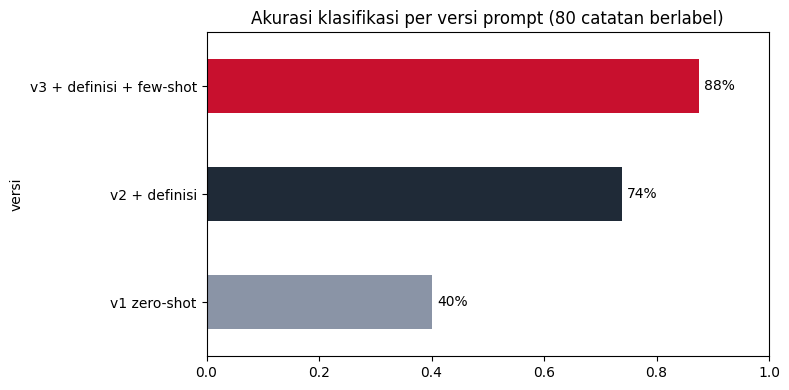

In [8]:
KATEGORI = list(TEMPLATE_CATATAN)

PROMPT_V1 = """TUGAS: KLASIFIKASI_CATATAN
Klasifikasikan catatan teknisi berikut ke salah satu kategori: {kategori}.
Jawab hanya nama kategori.
<<<{catatan}>>>"""

PROMPT_V2 = """TUGAS: KLASIFIKASI_CATATAN
Klasifikasikan catatan teknisi berikut ke salah satu kategori: {kategori}.
DEFINISI KATEGORI:
- Mesin: busi, katup, ruang bakar, coolant, gasket
- Kelistrikan: aki, sekring, ecu, spul
- Rem: kampas rem, cakram, master rem, minyak rem
- CVT/Transmisi: v-belt, pulley, per cvt
- Bodi: cover, tangki, dek
AKHIR_DEFINISI
Jawab hanya nama kategori.
<<<{catatan}>>>"""

CONTOH_FEWSHOT = """Contoh:
Catatan: Kiprok panas, aki cepat tekor => Kategori: Kelistrikan
Catatan: Roller aus, perlu ganti set => Kategori: CVT/Transmisi
Catatan: Klep kasar setelah turun mesin => Kategori: Mesin
Catatan: Tromol belakang aus => Kategori: Rem
Catatan: Visor tergores ringan => Kategori: Bodi
"""
PROMPT_V3 = PROMPT_V2.replace("Jawab hanya nama kategori.", CONTOH_FEWSHOT + "Jawab hanya nama kategori.")


def evaluasi_prompt(template, data, nama):
    prediksi = [llm.generate(template.format(kategori=KATEGORI, catatan=c)).strip() for c in data["catatan"]]
    akurasi = accuracy_score(data["label"], prediksi)
    return {"versi": nama, "akurasi": round(akurasi, 3), "prediksi": prediksi}


hasil_eval = [evaluasi_prompt(PROMPT_V1, data_uji, "v1 zero-shot"),
              evaluasi_prompt(PROMPT_V2, data_uji, "v2 + definisi"),
              evaluasi_prompt(PROMPT_V3, data_uji, "v3 + definisi + few-shot")]
tabel_eval = pd.DataFrame([{k: v for k, v in h.items() if k != "prediksi"} for h in hasil_eval])
display(tabel_eval)

ax = tabel_eval.plot.barh(x="versi", y="akurasi", legend=False, color=["#8A94A6", "#1F2A37", "#C8102E"])
ax.set_xlim(0, 1)
ax.set_title("Akurasi klasifikasi per versi prompt (80 catatan berlabel)")
for i, v in enumerate(tabel_eval["akurasi"]):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center")
plt.tight_layout()
plt.show()

**Penjelasan kode**
- `PROMPT_V1/V2/V3` — tiga versi prompt disimpan sebagai string berbeda. `PROMPT_V3` dibuat dari V2 dengan `.replace()` sehingga **hanya satu variabel yang berubah** (penambahan contoh) — prinsip eksperimen yang adil.
- Blok **DEFINISI KATEGORI** menerjemahkan istilah internal bengkel ke kategori; ini cara murah menyuntikkan *domain knowledge* perusahaan ke LLM. Definisi sengaja **tidak lengkap** (seperti di dunia nyata — tidak semua istilah terpikir saat menulis prompt), sehingga contoh few-shot masih memberi nilai tambah.
- Contoh few-shot **sengaja berbeda** dari data uji (mis. "Roller aus" vs "Roller peyang") agar tidak terjadi kebocoran jawaban (*data leakage*).
- `evaluasi_prompt()` — memanggil LLM untuk setiap catatan, lalu `accuracy_score(label_benar, prediksi)` menghitung proporsi yang benar.
- `{k: v for k, v in h.items() if k != "prediksi"}` — membuang list prediksi agar tabel ringkas.
- Grafik batang horizontal (`plot.barh`) dan `ax.text()` menuliskan persentase di ujung batang.

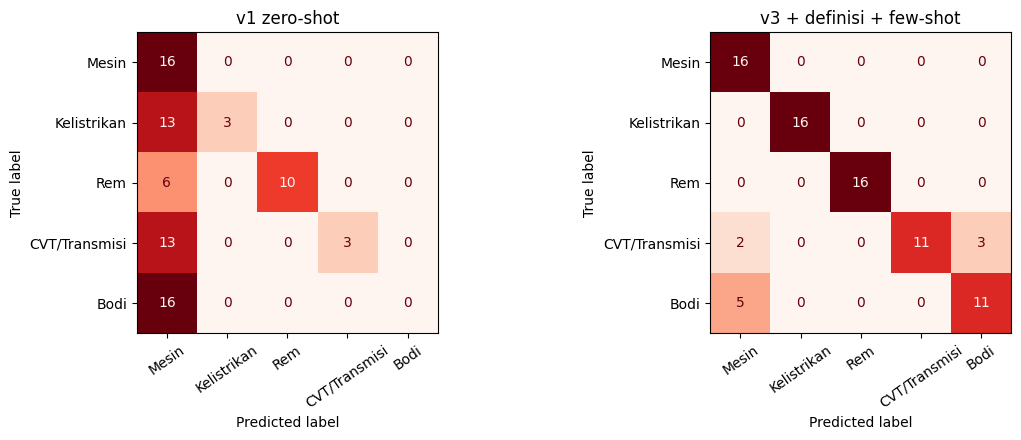

               precision    recall  f1-score   support

         Bodi       0.00      0.00      0.00        16
CVT/Transmisi       1.00      0.19      0.32        16
  Kelistrikan       1.00      0.19      0.32        16
        Mesin       0.25      1.00      0.40        16
          Rem       1.00      0.62      0.77        16

     accuracy                           0.40        80
    macro avg       0.65      0.40      0.36        80
 weighted avg       0.65      0.40      0.36        80



In [9]:
# Di mana v1 masih salah? Confusion matrix membantu menemukan pola kesalahan.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, h in zip(axes, [hasil_eval[0], hasil_eval[2]]):
    cm = confusion_matrix(data_uji["label"], h["prediksi"], labels=KATEGORI)
    ConfusionMatrixDisplay(cm, display_labels=KATEGORI).plot(ax=ax, cmap="Reds", colorbar=False)
    ax.set_title(h["versi"])
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

print(classification_report(data_uji["label"], hasil_eval[0]["prediksi"], zero_division=0))

**Penjelasan kode**
- `confusion_matrix(y_true, y_pred, labels=...)` — tabel baris = label benar, kolom = prediksi. Angka di luar diagonal = kesalahan.
- `ConfusionMatrixDisplay(...).plot(ax=...)` — menggambar matriks ke *axes* tertentu sehingga dua matriks tampil berdampingan.
- `classification_report` — menampilkan **precision** (dari yang diprediksi X, berapa yang benar), **recall** (dari yang sebenarnya X, berapa yang tertangkap), dan **f1-score**. `zero_division=0` mencegah peringatan saat suatu kelas tak pernah diprediksi.

**Insight:** zero-shot cenderung "melempar" catatan berjargon ke kategori *Mesin* (tebakan umum). Definisi & contoh memperbaiki recall kategori CVT, Kelistrikan, dan Bodi. Kesalahan yang tersisa pada v3 (mis. *spion*, *kampas ganda*) adalah bahan untuk iterasi prompt berikutnya — lihat Latihan 1.

## Teknik 4 — Output terstruktur + loop perbaikan otomatis (*self-correction*)
Kita mendefinisikan **skema** yang wajib dipenuhi. Jika jawaban LLM tidak sesuai, pesan error spesifik dikirim kembali ke LLM agar ia memperbaiki jawabannya sendiri.

In [10]:
SKEMA_INSIGHT = {                 # kunci wajib → tipe Python yang diharapkan
    "temuan": str,
    "angka_pendukung": dict,
    "rekomendasi": str,
    "tingkat_keyakinan": float,
}


def cek_skema(obj, skema):
    error = []
    for kunci, tipe in skema.items():
        if kunci not in obj:
            error.append(f"kunci '{kunci}' tidak ada")
        elif not isinstance(obj[kunci], tipe):
            error.append(f"'{kunci}' harus bertipe {tipe.__name__}, bukan {type(obj[kunci]).__name__}")
    return error


def minta_terstruktur(prompt_dasar, skema, maks_coba=3):
    prompt = prompt_dasar
    for i in range(1, maks_coba + 1):
        jawaban = llm.generate(prompt)
        try:
            obj = ambil_json(jawaban)
            error = cek_skema(obj, skema)
        except (ValueError, json.JSONDecodeError) as e:
            obj, error = None, [f"JSON tidak valid: {e}"]
        print(f"Percobaan {i}: {'VALID' if not error else error}")
        if not error:
            return obj
        # umpan balik error ke LLM → self-correction
        prompt = (prompt_dasar + "\n\nPERBAIKAN: jawaban sebelumnya tidak sesuai skema: "
                  + "; ".join(error) + ". Kembalikan JSON lengkap yang benar.")
    raise RuntimeError("Gagal mendapat output sesuai skema")


prompt_insight = f"""TUGAS: INSIGHT_TERSTRUKTUR
Berdasarkan statistik berikut, kembalikan JSON dengan kunci: temuan (string), angka_pendukung (objek),
rekomendasi (string), tingkat_keyakinan (angka 0-1).
STATISTIK: {json.dumps(statistik, ensure_ascii=False)}"""
insight = minta_terstruktur(prompt_insight, SKEMA_INSIGHT)
insight

Percobaan 1: ["kunci 'rekomendasi' tidak ada", "'tingkat_keyakinan' harus bertipe float, bukan str"]
Percobaan 2: VALID


{'temuan': 'Unit terjual Q2 turun dibanding Q1',
 'angka_pendukung': {'perubahan_%': -6.1},
 'rekomendasi': 'Telusuri penurunan per wilayah & metode bayar',
 'tingkat_keyakinan': 0.8}

**Penjelasan kode**
- `SKEMA_INSIGHT` — dict sederhana yang memetakan kunci wajib ke tipe data Python. (Di proyek besar, gunakan library seperti `pydantic` atau fitur *structured output* bawaan penyedia LLM.)
- `isinstance(nilai, tipe)` — memeriksa tipe. Misalnya `"tinggi"` bukan `float`, sehingga tertangkap.
- `tipe.__name__` — mengambil nama tipe (`"float"`) untuk pesan error yang mudah dibaca LLM.
- Loop `minta_terstruktur`: panggil → parsing → cek skema → jika gagal, **tambahkan pesan error spesifik** ke prompt lalu coba lagi. Pesan error yang spesifik ("kunci 'rekomendasi' tidak ada") jauh lebih efektif daripada sekadar "coba lagi".
- `raise RuntimeError` — setelah batas percobaan, gagal secara eksplisit agar tidak menghasilkan data rusak diam-diam.

## Teknik 5 — LLM menulis kode analisis, Python mengeksekusi dengan aman
LLM sangat membantu menulis kode pandas, tetapi **kode buatan AI tidak boleh dijalankan begitu saja**. Kita:
1. Menyusun prompt berisi *data dictionary* + pertanyaan + aturan (hasil di variabel `hasil`, tanpa import, tanpa menulis file).
2. Mengambil blok kode dari jawaban.
3. Memeriksa kode dengan `ast` (pohon sintaks) terhadap daftar larangan.
4. Menjalankan di *namespace* terbatas yang hanya berisi `df`, `pd`, `np`.

In [11]:
PROMPT_KODE = """TUGAS: TULIS_KODE
PERAN: Data analyst Python yang teliti.
KONTEKS:
{kamus}
ATURAN:
- Gunakan pandas; objek `df`, `pd`, dan `np` sudah tersedia. JANGAN menulis import.
- Simpan jawaban akhir di variabel bernama `hasil`.
- Jangan membaca/menulis file, jangan mengakses jaringan.
- Kembalikan satu blok kode ```python```.
PERTANYAAN: {pertanyaan} AKHIR_PERTANYAAN"""

NAMA_TERLARANG = {"open", "exec", "eval", "compile", "__import__", "os", "sys", "subprocess",
                  "shutil", "input", "globals", "locals", "getattr", "setattr", "delattr", "vars"}
METODE_TERLARANG = {"to_csv", "to_excel", "to_pickle", "to_sql", "to_parquet", "to_json"}


def ambil_blok_kode(teks):
    m = re.search(r"```(?:python)?\n(.*?)```", teks, flags=re.S)
    return (m.group(1) if m else teks).strip()


def periksa_kode(kode):
    pohon = ast.parse(kode)                               # error sintaks akan muncul di sini
    for node in ast.walk(pohon):                          # kunjungi setiap simpul pohon sintaks
        if isinstance(node, (ast.Import, ast.ImportFrom)):
            raise PermissionError("Kode mengandung import")
        if isinstance(node, ast.Name) and node.id in NAMA_TERLARANG:
            raise PermissionError(f"Nama terlarang: {node.id}")
        if isinstance(node, ast.Attribute) and (node.attr.startswith("__") or node.attr in METODE_TERLARANG):
            raise PermissionError(f"Atribut/metode terlarang: {node.attr}")


BUILTIN_AMAN = {"len": len, "round": round, "sum": sum, "min": min, "max": max,
                "sorted": sorted, "abs": abs, "dict": dict, "list": list, "str": str}


def tanya_data(pertanyaan, tampilkan_kode=True):
    jawaban = llm.generate(PROMPT_KODE.format(kamus=KAMUS_DATA, pertanyaan=pertanyaan))
    kode = ambil_blok_kode(jawaban)
    if tampilkan_kode:
        print(f"Q: {pertanyaan}\n--- kode dari LLM ---\n{kode}\n---------------------")
    periksa_kode(kode)
    ruang = {"df": df.copy(), "pd": pd, "np": np}
    exec(kode, {"__builtins__": BUILTIN_AMAN}, ruang)
    return ruang.get("hasil")


display(tanya_data("Wilayah mana dengan total pendapatan tertinggi (miliar Rupiah)?"))
display(tanya_data("Bagaimana tren unit terjual bulanan?"))

try:
    tanya_data("Hapus file data penjualan lama")
except PermissionError as e:
    print("⛔ DIBLOKIR:", e)

Q: Wilayah mana dengan total pendapatan tertinggi (miliar Rupiah)?
--- kode dari LLM ---
hasil = df.groupby("wilayah")["pendapatan"].sum().sort_values(ascending=False) / 1e9
---------------------


wilayah
Jabodetabek    180.055947
Jawa Barat     118.325156
Jawa Timur     108.325049
Jawa Tengah    106.233519
Sumatera        75.939979
Kalimantan      48.428920
Name: pendapatan, dtype: float64

Q: Bagaimana tren unit terjual bulanan?
--- kode dari LLM ---
hasil = df.groupby(df["tanggal"].dt.to_period("M"))["unit_terjual"].sum()
---------------------


tanggal
2026-01    4450
2026-02    4180
2026-03    4766
2026-04    4326
2026-05    4494
2026-06    4320
Freq: M, Name: unit_terjual, dtype: int64

Q: Hapus file data penjualan lama
--- kode dari LLM ---
import os
os.remove('data_penjualan.csv')
hasil = 'selesai'
---------------------
⛔ DIBLOKIR: Kode mengandung import


**Penjelasan kode**
- `re.search(r"```(?:python)?\n(.*?)```", teks, flags=re.S)` — *regular expression* untuk mengambil isi blok kode. `(?:python)?` = kata "python" opsional; `(.*?)` = ambil isi secukupnya (*non-greedy*); `re.S` agar `.` juga cocok dengan baris baru.
- `ast.parse(kode)` — mengubah teks kode menjadi **pohon sintaks** tanpa menjalankannya. `ast.walk()` menelusuri semua simpul:
  - `ast.Import/ImportFrom` → memblokir `import os`, dll.
  - `ast.Name` → memblokir pemanggilan nama berbahaya (`open`, `eval`, `os`…).
  - `ast.Attribute` → memblokir atribut *dunder* (`__class__`, trik klasik untuk lolos sandbox) dan metode penulis file (`to_csv`…).
- `exec(kode, {"__builtins__": BUILTIN_AMAN}, ruang)` — menjalankan kode dengan hanya segelintir fungsi bawaan; `ruang` berisi **salinan** `df` sehingga data asli tidak bisa diubah.
- `ruang.get("hasil")` — mengambil variabel `hasil` yang dibuat kode LLM.
- Percobaan "Hapus file" menunjukkan kode berbahaya **ditolak sebelum dijalankan**.

> ⚠️ Pemeriksaan ini adalah lapisan pengaman dasar untuk pembelajaran. Untuk produksi, jalankan kode AI di lingkungan terisolasi (container/akun read-only) dan tetap lakukan review manusia.

## Teknik 6 — *Prompt chaining*: rencana → kode → interpretasi
Pertanyaan bisnis yang kompleks ("**Mengapa** penjualan Q2 turun di Jawa Timur?") dipecah menjadi rantai prompt kecil. Setiap mata rantai punya tugas sempit sehingga lebih akurat dan mudah diperiksa.

In [12]:
pertanyaan_bisnis = "Mengapa penjualan Q2 2026 turun, terutama di wilayah yang paling terdampak?"

# Mata rantai 1: LLM menyusun rencana analisis (daftar sub-pertanyaan)
rencana = ambil_json(llm.generate(f"""TUGAS: RENCANA_ANALISIS
Anda analis Sales Planning. Pecah pertanyaan bisnis berikut menjadi maksimal 3 langkah analisis data
yang dapat dijawab dengan data berikut. Jawab sebagai JSON array berisi kalimat.
{KAMUS_DATA}
PERTANYAAN BISNIS: {pertanyaan_bisnis}"""))
print("RENCANA:", *rencana, sep="\n  - ")

# Mata rantai 2: setiap langkah → kode → hasil (dieksekusi aman)
hasil_langkah = {}
for i, langkah in enumerate(rencana, start=1):
    tabel = tanya_data(langkah, tampilkan_kode=False)
    print(f"\nLangkah {i}: {langkah}")
    display(tabel)
    hasil_langkah[f"langkah_{i}"] = json.loads(tabel.to_json())

# Mata rantai 3: LLM menafsirkan HASIL (bukan data mentah)
interpretasi = llm.generate(f"""TUGAS: INTERPRETASI
Tafsirkan hasil analisis berikut untuk menjawab: {pertanyaan_bisnis}
Sebutkan angka kunci, susun hipotesis penyebab, dan 1 rekomendasi. Jangan mengarang angka.
HASIL: {json.dumps(hasil_langkah, ensure_ascii=False)} AKHIR_HASIL""")
print("\n=== INTERPRETASI ===\n" + interpretasi)

RENCANA:
  - Bandingkan total unit Q1 vs Q2 per wilayah
  - Rinci unit Jawa Timur per model untuk Q1 vs Q2
  - Bandingkan proporsi metode bayar Jawa Timur per kuartal

Langkah 1: Bandingkan total unit Q1 vs Q2 per wilayah


kuartal,Q1,Q2,perubahan_%
wilayah,,,
Jawa Timur,2438,1945,-20.2
Jawa Tengah,2269,2194,-3.3
Kalimantan,1005,1011,0.6
Jawa Barat,2441,2484,1.8
Jabodetabek,3679,3852,4.7
Sumatera,1564,1654,5.8



Langkah 2: Rinci unit Jawa Timur per model untuk Q1 vs Q2


kuartal,Q1,Q2,perubahan_%
model,,,
BeAT,742,385,-48.1
Scoopy,370,196,-47.0
Supra X 125,242,207,-14.5
PCX 160,261,244,-6.5
CB150 Verza,131,126,-3.8
CBR150R,160,180,12.5
Vario 125,532,607,14.1



Langkah 3: Bandingkan proporsi metode bayar Jawa Timur per kuartal


metode_bayar,Kredit,Tunai
kuartal,,
Q1,74.1,25.9
Q2,64.7,35.3



=== INTERPRETASI ===
1) Penurunan terbesar Q2 vs Q1 terjadi di Jawa Timur (-20.2%).
2) Di Jawa Timur, penurunan terkonsentrasi pada BeAT (-48.1%) dan Scoopy (-47.0%) — segmen entry level.
3) Porsi kredit turun dari 74.1% (Q1) menjadi 64.7% (Q2).
Hipotesis: pengetatan persetujuan leasing untuk segmen entry di Jawa Timur. Rekomendasi: validasi data approval rate leasing & program DP ringan bersama mitra pembiayaan.


**Penjelasan kode**
- **Mata rantai 1** — LLM hanya diminta membuat *rencana* (bukan jawaban). Ini membuat proses berpikirnya **terlihat dan dapat diperiksa** sebelum ada angka yang dihitung.
- `print(*rencana, sep="\n  - ")` — operator `*` membuka list menjadi argumen terpisah; `sep` menjadi pemisah antar item.
- **Mata rantai 2** — setiap sub-pertanyaan memakai fungsi `tanya_data()` (Teknik 5), sehingga semua angka **dihitung Python**.
- `tabel.to_json()` lalu `json.loads(...)` — mengubah DataFrame menjadi dict bertingkat (`{kolom: {indeks: nilai}}`) agar bisa dikirim ke LLM.
- **Mata rantai 3** — LLM menafsirkan tabel hasil. Hipotesis yang muncul (pengetatan leasing segmen entry di Jawa Timur) sesuai dengan pola yang kita tanam di Langkah 1.

**Mengapa chaining lebih baik daripada satu prompt raksasa?** Tiap langkah bisa diuji terpisah, kesalahan mudah dilokalisasi, dan manusia dapat menyetujui rencana sebelum eksekusi.

## Teknik 7 — *Self-consistency*: tanya beberapa kali, ambil suara terbanyak
Untuk kasus ambigu, jawaban LLM dengan `temperature > 0` bisa berbeda-beda. Kita panggil **N kali**, lalu ambil **mayoritas**. Tingkat kesepakatan menjadi ukuran keyakinan: rendah → kirim ke manusia.

In [13]:
def self_consistency(catatan, n=7):
    prompt = PROMPT_V3.format(kategori=KATEGORI, catatan=catatan) + "\nSUHU_TINGGI"   # penanda temperature>0 untuk simulator
    suara = [llm.generate(prompt, temperature=0.8).strip() for _ in range(n)]
    hitung = Counter(suara)
    jawaban, jumlah = hitung.most_common(1)[0]
    return {"catatan": catatan, "jawaban": jawaban, "kesepakatan": round(jumlah / n, 2), "sebaran": dict(hitung)}


kasus = ["Bunyi kasar dari bagian bawah saat jalan pelan",   # ambigu
         "Kiprok rusak, aki tidak mengisi"]                   # jelas
tabel_sc = pd.DataFrame([self_consistency(k) for k in kasus])
tabel_sc["tindakan"] = np.where(tabel_sc["kesepakatan"] >= 0.8, "otomatis", "review manusia")
tabel_sc

,catatan,jawaban,kesepakatan,sebaran,tindakan
0,Bunyi kasar dari bagian bawah saat jalan pelan,CVT/Transmisi,0.57,"{'Mesin': 3, 'CVT/Transmisi': 4}",review manusia
1,"Kiprok rusak, aki tidak mengisi",Kelistrikan,1.00,{'Kelistrikan': 7},otomatis


**Penjelasan kode**
- `temperature=0.8` — menaikkan keacakan agar terlihat variasi penalaran model. (Di simulator, penanda `SUHU_TINGGI` mengaktifkan variasi.)
- `Counter(suara)` — menghitung frekuensi tiap jawaban; `most_common(1)[0]` mengambil pasangan (jawaban, jumlah) terbanyak.
- `kesepakatan = jumlah / n` — proporsi suara mayoritas. Catatan jelas → 100%; catatan ambigu → lebih rendah.
- `np.where(kondisi, "otomatis", "review manusia")` — *if-else* vektor: memberi keputusan untuk setiap baris sekaligus.
- *Trade-off:* self-consistency memanggil LLM N kali → biaya N kali lipat. Gunakan hanya untuk keputusan penting atau kasus yang terdeteksi ambigu.

## Teknik 8 — *Prompt library* & versioning
Prompt yang sudah teruji disimpan bersama **metadata** (versi, tanggal, akurasi, pemilik) agar bisa dipakai ulang oleh seluruh divisi dan diaudit.

In [14]:
prompt_library = {
    "klasifikasi_catatan_teknisi": [
        {"versi": "v1", "template": PROMPT_V1, "akurasi": hasil_eval[0]["akurasi"], "status": "arsip"},
        {"versi": "v2", "template": PROMPT_V2, "akurasi": hasil_eval[1]["akurasi"], "status": "arsip"},
        {"versi": "v3", "template": PROMPT_V3, "akurasi": hasil_eval[2]["akurasi"], "status": "produksi"},
    ],
    "tulis_kode_pandas": [{"versi": "v1", "template": PROMPT_KODE, "akurasi": None, "status": "produksi"}],
}
for nama, versi in prompt_library.items():
    for v in versi:
        v.update({"pemilik": "Tim Data Analytics", "diperbarui": "2026-09-30"})

with open("prompt_library.json", "w", encoding="utf-8") as f:
    json.dump(prompt_library, f, ensure_ascii=False, indent=2)

pd.DataFrame([{"prompt": k, **{kk: vv for kk, vv in v.items() if kk != "template"}}
              for k, vs in prompt_library.items() for v in vs])

,prompt,versi,akurasi,status,pemilik,diperbarui
0,klasifikasi_catatan_teknisi,v1,0.400,arsip,Tim Data Analytics,2026-09-30
1,klasifikasi_catatan_teknisi,v2,0.738,arsip,Tim Data Analytics,2026-09-30
2,klasifikasi_catatan_teknisi,v3,0.875,produksi,Tim Data Analytics,2026-09-30
3,tulis_kode_pandas,v1,NaN,produksi,Tim Data Analytics,2026-09-30


**Penjelasan kode**
- `prompt_library` — struktur dict: nama tugas → list versi. Setiap versi menyimpan template, akurasi hasil evaluasi, dan status (produksi/arsip).
- `v.update({...})` — menambahkan metadata ke setiap entri.
- `json.dump(..., indent=2)` — menyimpan library ke file JSON yang bisa di-*commit* ke Git atau SharePoint tim.
- *List comprehension* bersarang `for k, vs in ... for v in vs` — meratakan struktur bertingkat menjadi tabel.

## Ringkasan teknik
| Teknik | Kapan dipakai | Ukuran keberhasilan |
|---|---|---|
| Anatomi 5 komponen | Semua prompt | Jawaban spesifik & bisa diverifikasi |
| Data dictionary | Minta kode/analisis | Kode benar tanpa kirim data mentah |
| Definisi + few-shot | Klasifikasi berjargon | Akurasi pada data berlabel |
| Skema + self-correction | Output untuk mesin | % JSON valid |
| Kode + pemeriksaan AST | Analisis ad-hoc | Kode aman & hasil benar |
| Prompt chaining | Pertanyaan "mengapa" | Rencana dapat diperiksa |
| Self-consistency | Kasus ambigu/penting | Tingkat kesepakatan |
| Prompt library | Skala tim | Reuse & audit |

## Latihan
1. Tambahkan 2 contoh few-shot baru pada `PROMPT_V3` untuk kategori yang masih sering salah, lalu ukur ulang akurasinya.
2. Tulis pertanyaan baru untuk `tanya_data()`, misalnya *"Berapa rata-rata harga OTR per tipe?"* dan tambahkan pola kodenya di simulator (atau uji langsung dengan LLM sungguhan).
3. Coba "serang" pemeriksa kode: tulis kode yang memakai `df.to_csv(...)` — apakah terblokir? Bagaimana dengan `getattr(df, "to_csv")`?
4. Ubah ambang kesepakatan self-consistency menjadi 0,9 — kasus mana yang berubah tindakan?